# Lung: complete cell–ECM experiment

Recompute the six-ROI analysis, replay the fold-specific selected settings,
and fit both mouse-held-out reconstruction folds. All three contexts and the
label-prior baseline use five corruption realisations. The final section adds
ROI-held-out, block/isolated-corruption and training-fold ECM-partition controls.

**Estimated runtime:** 2–5 minutes for the primary analysis; allow 5–10 minutes
including the supplementary controls on an eight-thread CPU. Installation
and the first data download are excluded. The complete notebook uses CPU only.

The selected graph, feature, classifier and cleaning settings were chosen
within each original training fold. Their inner searches are not rerun.

## Setup

On Colab, keep **Latest** and select **CPU**. Run this cell, restart the
session if requested, then run all cells. Locally, install
`lung_requirements.txt` and keep the companion files beside the notebook.

In [1]:
from pathlib import Path
import hashlib
from urllib.request import urlopen

_SETUP = Path("experiment_setup.py")
_SETUP_SHA256 = "6faab2e74f2559b2cc76cbb5b0323215a58e15ab2fb355050c55822de4214175"
if not _SETUP.exists():
    with urlopen("https://raw.githubusercontent.com/moeghaf/mantpy_reproducibility/mantpy-api-v1.1.0/notebooks/experiments/experiment_setup.py", timeout=90) as response:
        _setup_bytes = response.read()
    if hashlib.sha256(_setup_bytes).hexdigest() != _SETUP_SHA256:
        raise RuntimeError("Downloaded setup checksum does not match this notebook.")
    _setup_temp = _SETUP.with_name(_SETUP.name + ".download")
    _setup_temp.write_bytes(_setup_bytes)
    _setup_temp.replace(_SETUP)
if hashlib.sha256(_SETUP.read_bytes()).hexdigest() != _SETUP_SHA256:
    raise RuntimeError("Use the setup file matching this notebook release.")
from experiment_setup import prepare_experiment
ASSETS = prepare_experiment("lung")


site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1031 09:46:35.470000 9876 torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


Lung files and matching Mantpy APIs verified.


In [2]:
import json
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mantpy as mt
from threadpoolctl import threadpool_limits
from lung_analysis.graphs import GraphRecipe
from lung_analysis.pipeline import GraphCache
from lung_analysis.realisations import make_realisation
import lung_helpers as H

SEED = 0
PATCH_SIZE = 10
WALL_CLUSTER = 1
EVALUATION_SEEDS = list(range(5))
KINDS = ("mixed", "block", "isolated")
RUN_SUPPLEMENTARY = True
RUN_TARGET_REFIT_CONTROL = True
RESULTS = Path("results/lung")
RESULTS.mkdir(parents=True, exist_ok=True)
threadpool_limits(limits=int(os.environ.get("OMP_NUM_THREADS", "8")))
np.random.seed(SEED)
selected = H.load_selections()
stage_times = {}
experiment_started = time.perf_counter()

## Load all six ROIs

In [3]:
started = time.perf_counter()
cache_dir = Path(os.environ.get("MANTPY_CACHE", "data"))
bundle = mt.datasets.balbc_pbs_lung(cache_dir=cache_dir)
cells = bundle.cohort_cells
SHOWCASE = bundle.showcase_roi
assert len(cells) == 6 and bundle.metadata["Mouse"].nunique() == 2
stage_times["data_loading"] = time.perf_counter() - started
bundle.metadata[["sample_id", "Mouse", "strain", "treatment"]]

,sample_id,Mouse,strain,treatment
0,roi_001,mouse_01,BALB/c,PBS
1,roi_002,mouse_01,BALB/c,PBS
2,roi_003,mouse_01,BALB/c,PBS
3,roi_004,mouse_02,BALB/c,PBS
4,roi_005,mouse_02,BALB/c,PBS
5,roi_006,mouse_02,BALB/c,PBS


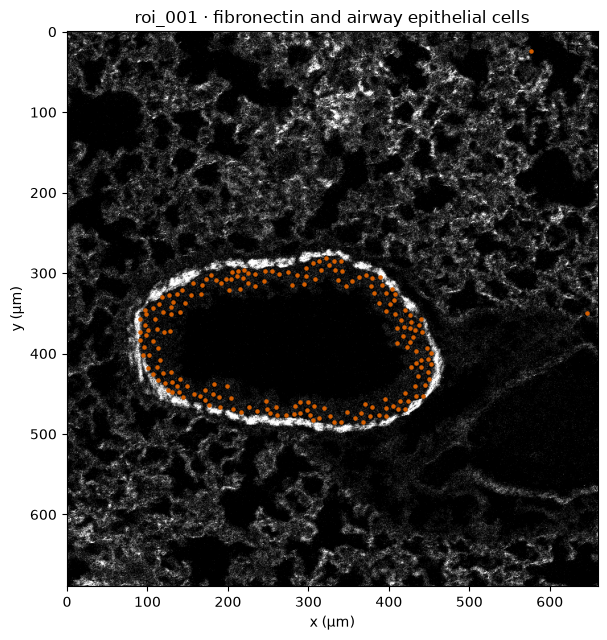

In [4]:
panel = bundle.panel.loc[bundle.panel["keep"].eq(1)].reset_index(drop=True)
fn_index = int(panel.index[panel["name"].eq("Fibronectin")][0])
raw_fn = np.asarray(bundle.images[SHOWCASE][fn_index], dtype=float)
vmax = np.percentile(raw_fn[raw_fn > 0], 99)
aec = cells[SHOWCASE].obs["cell_type"].astype(str).eq("AEC").to_numpy()
xy = np.asarray(cells[SHOWCASE].obsm["spatial"])
plt.figure(figsize=(6.5, 6.5))
plt.imshow(raw_fn, cmap="gray", vmin=0, vmax=vmax)
plt.scatter(xy[aec, 0], xy[aec, 1], s=5, c="#D55E00", label="AEC")
plt.xlabel("x (µm)")
plt.ylabel("y (µm)")
plt.title(f"{SHOWCASE} · fibronectin and airway epithelial cells")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

## Recompute the selected ECM partition

Standardise each marker over the pooled pixels, extract ten-pixel patches,
retain patches strictly above each ROI's minimum mean feature value,
fit four K-means components and remove the lowest-signal component.
Signal clusters are ordered by size. This is a fresh fit.

In [5]:
started = time.perf_counter()
ecm = mt.pp.ecm_patches_from_images(
    bundle.images, bundle.panel, normalize="pooled_zscore",
    patch_size=PATCH_SIZE, features=["mean"],
    ecm_K=None, background_quantile=0.0,
)
primary_support = H.retain_primary_patch_support(ecm)
partition = mt.pp.cluster_ecm_patches(
    ecm, n_clusters=4, method="kmeans", subset="all",
    random_state=SEED, n_init=10,
)
background = mt.pp.remove_background_patches(
    ecm, partition, background="lowest_mean", order_signal_by="size",
)
cohort = H.cohort_from_mantpy(bundle, ecm, PATCH_SIZE)
total = sum(len(r.label) for r in cohort.rois.values())
signal = sum(int((r.label >= 0).sum()) for r in cohort.rois.values())
stage_times["partition"] = time.perf_counter() - started
print(f"{total:,} patches; {signal:,} signal patches in three ECM clusters.")
print("Paper reference: 27,318 patches; 11,435 signal patches.")

27,318 patches; 11,450 signal patches in three ECM clusters.
Paper reference: 27,318 patches; 11,435 signal patches.


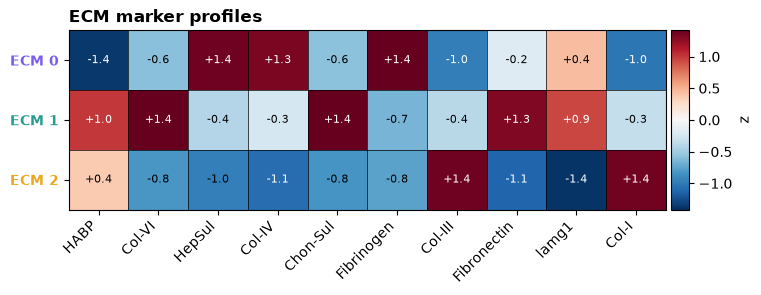

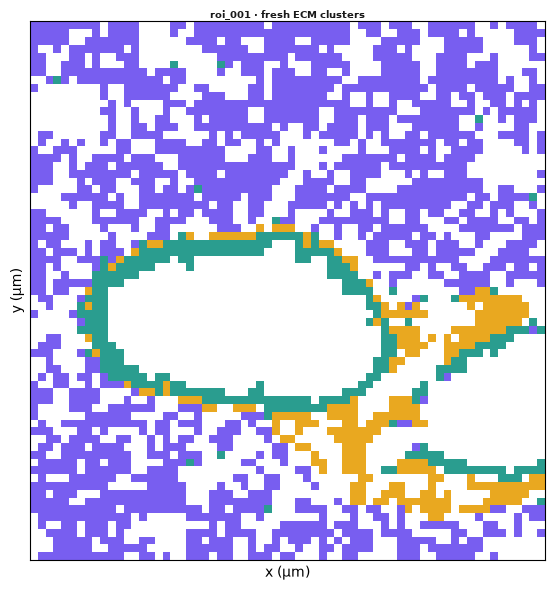

In [6]:
mt.pl.ecm_centroid_heatmap(
    ecm, ecm_names=bundle.ecm_names, K_ecm=3,
    cluster_colors=bundle.ecm_palette, title="ECM marker profiles",
    figsize=(8, 4),
)
H.plot_map(
    cohort.rois[SHOWCASE], cohort.rois[SHOWCASE].label,
    f"{SHOWCASE} · fresh ECM clusters", bundle.ecm_palette,
)

## Descriptive graphs and associations

The reference graph connects cells within 15 pixels, adjacent ECM patches
on an eight-connected grid, and each cell to its five nearest patches within
15 pixels. Background patches remain unlabelled nodes and are excluded from
association counts.

In [7]:
started = time.perf_counter()
mt.pp.attach_ecm_patches(cells, ecm)
graph_result = mt.gr.build_cell_ecm_graphs(
    cells, cell_graph="squidpy", cell_radius=(0, 15),
    ecm_edge_method="grid", ecm_grid_connectivity=8,
    cell_ecm_edge_method="knn", cell_ecm_k=5, cell_ecm_Dmax=15,
)
graph_counts = pd.DataFrame([vars(row) for row in graph_result.summaries])
cache = GraphCache(96)
reference = GraphRecipe.from_dict(selected["reference_graph"])
# The helper adapts the original matrices to mt.gr.joint_graph_from_connectivities;
# mt.tl.cell_ecm_enrichment_matrix pools the original per-ROI expected counts.
association, per_roi_association = H.descriptive_association(cohort, cache, reference)
stage_times["descriptive_graphs_and_association"] = time.perf_counter() - started
graph_counts

site-packages\docrep\decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
site-packages\docrep\decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
Mantpy\src\mantpy\gr.py:1686: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(adata, **sq_kwargs)
Mantpy\src\mantpy\gr.py:1686: FutureWarning: Parameter `n_neighs` is ignored when `radius` is set use `spatial_neighbors_radius` instead.
  sq.gr.spatial_neighbors(adata, **sq_kwargs)
Mantpy\src\mantpy\gr.py:1686: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_nei

,sample,n_nodes,n_cells,n_ecm,cell_cell_edges,ecm_ecm_edges,cell_ecm_edges
0,roi_001,6373,1820,4553,3029,17805,9046
1,roi_002,6456,1903,4553,3308,17805,9450
2,roi_003,6515,1962,4553,3248,17805,9739
3,roi_004,6495,1942,4553,3861,17805,9639
4,roi_005,6377,1824,4553,3261,17805,9043
5,roi_006,6350,1797,4553,2812,17805,8914


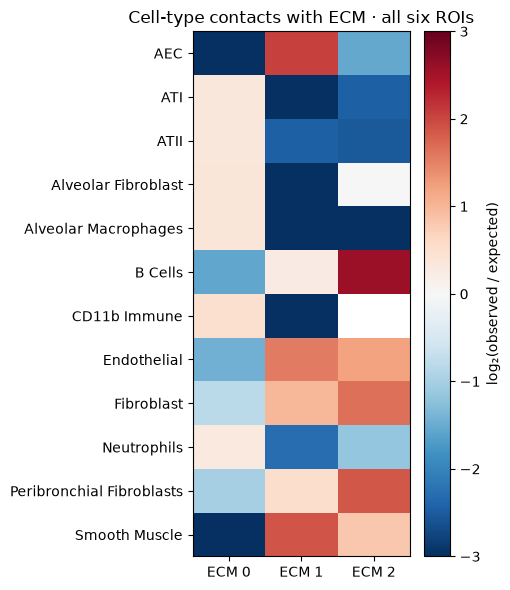

In [8]:
matrix = association.pivot(index="cell_type", columns="cluster", values="log2_enr")
plt.figure(figsize=(5, 6))
plt.imshow(matrix.to_numpy(), cmap="RdBu_r", vmin=-3, vmax=3, aspect="auto")
plt.xticks(range(3), ["ECM 0", "ECM 1", "ECM 2"])
plt.yticks(range(len(matrix)), matrix.index)
plt.colorbar(label="log₂(observed / expected)")
plt.title("Cell-type contacts with ECM · all six ROIs")
plt.tight_layout()
plt.show()

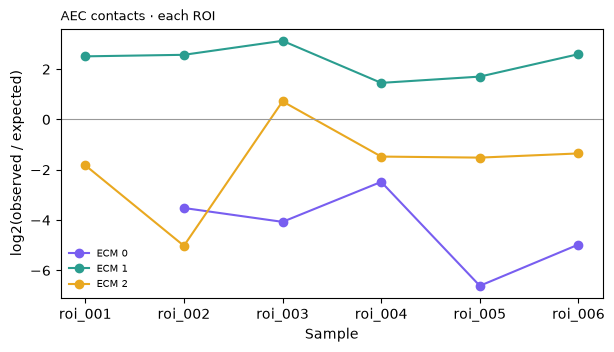

,roi,mouse,cluster,n_obs,n_exp,log2_enr
0,roi_001,mouse_01,0,0,279.665914,-inf
1,roi_001,mouse_01,1,367,64.505643,2.508283
2,roi_001,mouse_01,2,9,31.828442,-1.822320
36,roi_002,mouse_01,0,24,275.212766,-3.519441
37,roi_002,mouse_01,1,340,57.287234,2.569249
38,roi_002,mouse_01,2,1,32.500000,-5.022368
72,roi_003,mouse_01,0,18,302.512864,-4.070928
73,roi_003,mouse_01,1,316,36.190637,3.126236
74,roi_003,mouse_01,2,12,7.296499,0.717758
108,roi_004,mouse_02,0,97,541.721766,-2.481495


In [9]:
aec_effects = per_roi_association.query("cell_type == 'AEC'").copy()
mt.pl.cell_ecm_enrichment_per_roi(
    aec_effects, cluster_colors=bundle.ecm_palette,
    title="AEC contacts · each ROI", figsize=(7, 3.5),
)
aec_effects[["roi", "mouse", "cluster", "n_obs", "n_exp", "log2_enr"]]

## Matrix contacted by airway epithelial cells

Within ECM 1, count each patch once. Subtract the mean marker profile of
uncontacted patches from that of AEC-contacted patches within each ROI, then
average the six ROIs with equal weight.

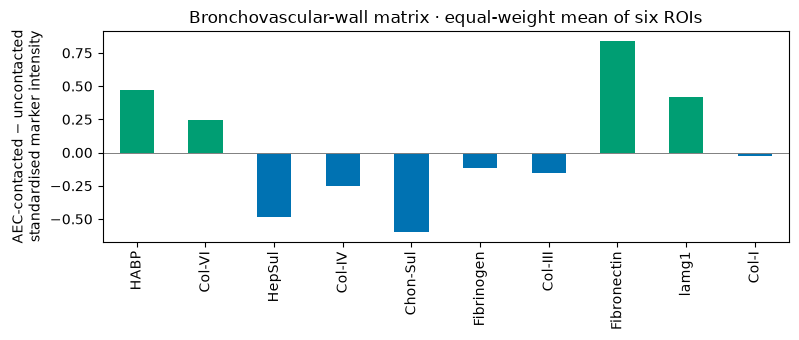

,HABP,Col-VI,HepSul,Col-IV,Chon-Sul,Fibrinogen,Col-III,Fibronectin,lamg1,Col-I
roi,,,,,,,,,,
roi_001,0.404,0.457,-0.375,-0.185,-1.027,-0.101,-0.232,1.047,0.667,-0.036
roi_002,0.242,0.961,-0.371,-0.189,-0.592,-0.108,-0.289,2.313,0.988,-0.034
roi_003,0.793,-0.535,-0.440,-0.760,0.179,-0.433,0.055,0.117,0.012,0.138
roi_004,0.519,-0.129,-0.519,-0.107,-0.716,-0.007,-0.256,0.263,0.092,-0.224
roi_005,0.332,0.508,-0.471,-0.034,-1.185,-0.008,-0.036,0.660,0.395,0.040
roi_006,0.523,0.190,-0.716,-0.251,-0.247,-0.062,-0.186,0.643,0.338,-0.046


In [10]:
# Public contact_marker_contrast preserves unique contacted patches and input-dtype means.
contacts = H.aec_contacts(cohort, cache, reference)
contrasts = H.marker_contrasts(cohort, contacts, WALL_CLUSTER)
mean_contrast = contrasts.mean(axis=0)
mean_contrast.plot.bar(
    figsize=(8, 3.5), color=np.where(mean_contrast >= 0, "#009E73", "#0072B2"),
)
plt.axhline(0, color="gray", linewidth=0.7)
plt.ylabel("AEC-contacted − uncontacted\nstandardised marker intensity")
plt.title("Bronchovascular-wall matrix · equal-weight mean of six ROIs")
plt.tight_layout()
plt.show()
contrasts.round(3)

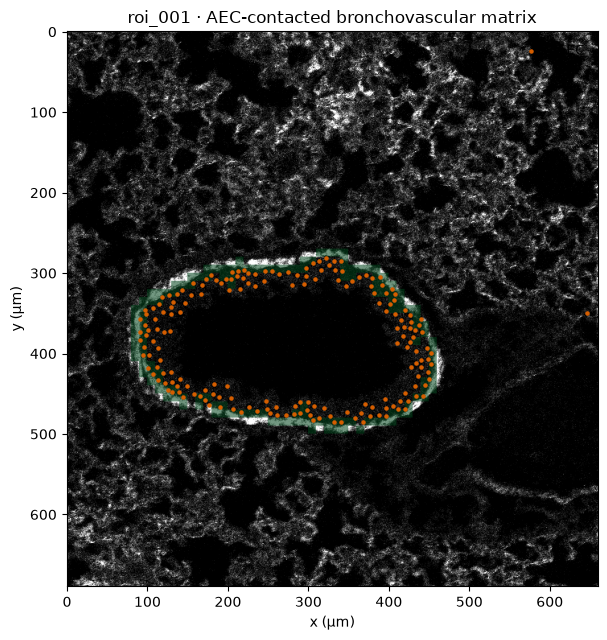

In [11]:
roi = cohort.rois[SHOWCASE]
hit = contacts[SHOWCASE] & (roi.label == WALL_CLUSTER)
overlay = np.zeros(raw_fn.shape, dtype=bool)
for x, y in roi.patch_xy[hit]:
    x0, y0 = int(x - PATCH_SIZE / 2), int(y - PATCH_SIZE / 2)
    overlay[y0:y0 + PATCH_SIZE, x0:x0 + PATCH_SIZE] = True
plt.figure(figsize=(6.5, 6.5))
plt.imshow(raw_fn, cmap="gray", vmin=0, vmax=vmax)
plt.imshow(np.ma.masked_where(~overlay, overlay), cmap="Greens",
           vmin=0, vmax=1, alpha=0.55)
plt.scatter(xy[aec, 0], xy[aec, 1], s=5, c="#D55E00", label="AEC")
plt.xlabel("x (µm)")
plt.ylabel("y (µm)")
plt.title(f"{SHOWCASE} · AEC-contacted bronchovascular matrix")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

## Sensitivity to the cell–ECM edge rule

Recompute the 48 seeded graph recipes and reference recipe used for the
descriptive sensitivity analysis. These are effect-size comparisons.

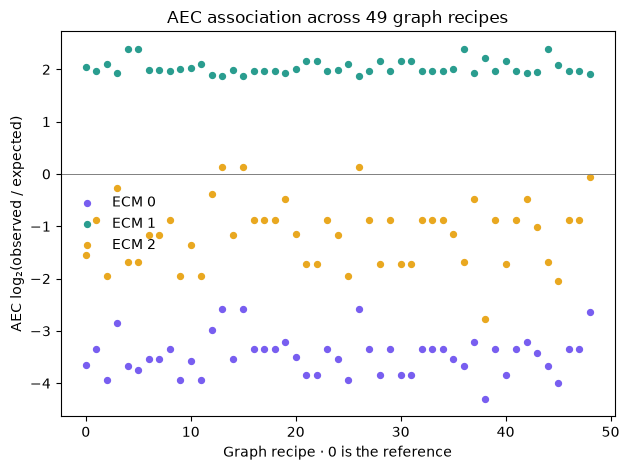

In [12]:
started = time.perf_counter()
sensitivity = H.graph_sensitivity(cohort, selected, RESULTS)
stage_times["graph_sensitivity"] = time.perf_counter() - started
for cluster in range(3):
    subset = sensitivity.loc[sensitivity.cluster.eq(cluster)]
    plt.scatter(subset.recipe_index, subset.log2_enr,
                s=18, c=bundle.ecm_palette[cluster], label=f"ECM {cluster}")
plt.axhline(0, color="gray", linewidth=0.7)
plt.xlabel("Graph recipe · 0 is the reference")
plt.ylabel("AEC log₂(observed / expected)")
plt.title("AEC association across 49 graph recipes")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

## Replay the mouse-held-out selections

Each mouse has its own selected graph, feature, classifier and cleaning
recipe. Fit on the other mouse's three pristine ROIs. Training-only
standardisation and any selected temperature calibration are refitted.
The patch's own ECM label is excluded from its context features.

In [13]:
H.selection_table(selected, "mouse").round(4)

,held_out,context,cell–ECM,ECM–ECM,weight,features,hops,penalty,C,threshold,passes,calibration,original_inner_score
0,mouse_01,cell,radius,grid8,gaussian_median,count,1,elasticnet,1.1101,2.9922,1,none,0.9512
1,mouse_01,ecm,delaunay,knn,inv_d,fraction,2,none,0.0358,2.8218,2,temperature,0.9299
2,mouse_01,joint,delaunay,knn,none,count,2,l2,0.0349,0.3601,3,none,0.9492
3,mouse_02,cell,knn,grid8,inv_d,fraction,2,l1,31.0669,0.9499,1,none,0.9668
4,mouse_02,ecm,knn,radius,none,fraction,2,l2,0.0188,0.5189,1,temperature,0.9325
5,mouse_02,joint,radius,delaunay,inv_d,fraction,1,l2,94.1941,0.9429,3,none,0.9438


In [14]:
protocol = {"benchmark": selected["benchmark"]}
realisations = {
    (kind, seed): make_realisation(cohort, "forward", kind, seed, protocol)
    for kind in KINDS for seed in EVALUATION_SEEDS
}
for (_, seed), real in realisations.items():
    for name, corruption in real.items():
        expected = round(0.1 * int((cohort.rois[name].label >= 0).sum()))
        assert int(corruption.is_artifact.sum()) == expected
print("Five independent evaluation realisations for each corruption type.")

Five independent evaluation realisations for each corruption type.


mouse_01 · cell: 15 held-out scores


mouse_01 · joint: 15 held-out scores


.\work\fig2_env\Lib\site-packages\sklearn\linear_model\_logistic.py:1232: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(


mouse_01 · ecm: 15 held-out scores
mouse_01 · prior: 15 held-out scores


.\work\fig2_env\Lib\site-packages\sklearn\linear_model\_logistic.py:1221: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l1)
  warnings.warn(


mouse_02 · cell: 15 held-out scores


mouse_02 · joint: 15 held-out scores


mouse_02 · ecm: 15 held-out scores
mouse_02 · prior: 15 held-out scores


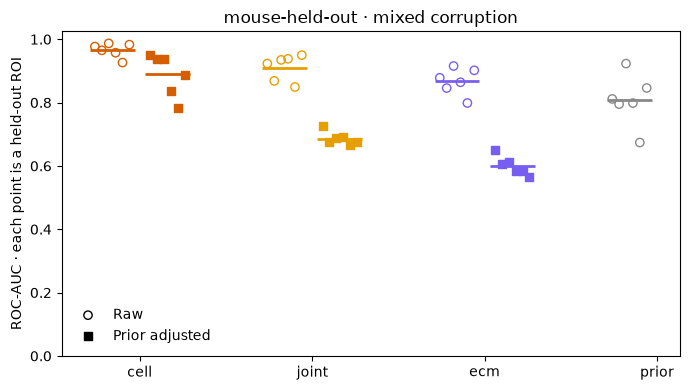

roc_auc  prior_adjusted_roc_auc  pr_auc  \
scheme context kind                                             
mouse  cell    mixed   0.9660                  0.8891  0.7907   
       joint   mixed   0.9107                  0.6864  0.6788   
       ecm     mixed   0.8674                  0.6005  0.6154   
       prior   mixed   0.8081                     NaN  0.3019   

                      prior_adjusted_pr_auc  accuracy_before  accuracy_after  \
scheme context kind                                                            
mouse  cell    mixed                 0.6794              0.9          0.9507   
       joint   mixed                 0.5259              0.9          0.9353   
       ecm     mixed                 0.4736              0.9          0.9309   
       prior   mixed                    NaN              0.9          0.9000   

                      recovery  pristine_relabel_rate  correction_precision  \
scheme context kind                                                           
mouse  cell    mixed    0.6944                 0.0208                0.7639   
       joint   mixed    0.5193                 0.0185                0.7391   
       ecm     mixed    0.4270                 0.0132                0.7677   
       prior   mixed    0.0000                 0.0000                   NaN   

                      macro_f1_after  balanced_accuracy_after  
scheme context kind                                            
mouse  cell    mixed          0.9102                   0.9106  
       joint   mixed          0.8803                   0.9008  
       ecm     mixed          0.8750                   0.8992  
       prior   mixed          0.8329                   0.8974

In [15]:
started = time.perf_counter()
primary_rows, primary_classes, supplementary_mouse_rows = [], [], []
fold_records, examples, primary_fits = [], {}, {}
for held_out in cohort.mice():
    for context in H.CONTEXTS:
        fitted = H.fit_fold(
            cohort, selected, "mouse", held_out, context,
            cache, RESULTS / "checkpoints",
        )
        scores, class_counts, maps = H.score_fold(
            fitted, cohort, realisations, cache, kinds=("mixed",),
        )
        primary_rows.append(scores)
        primary_classes.append(class_counts)
        fold_records.append(H.fold_record(fitted))
        primary_fits[(held_out, context)] = fitted
        if context == "cell":
            examples.update(maps)
        print(f"{held_out} · {context}: {len(scores)} held-out scores")
primary = pd.concat(primary_rows, ignore_index=True)
class_counts = pd.concat(primary_classes, ignore_index=True)
assert len(primary) == 120
assert primary.groupby(["context", "roi"]).size().eq(5).all()
per_roi_scores, score_summary = H.summarise_scores(primary)
per_roi_recovery, recovery_summary = H.summarise_class_recovery(class_counts)
stage_times["mouse_held_out_fitting_and_scoring"] = time.perf_counter() - started
H.plot_detection(per_roi_scores)
score_summary.xs("mean", axis=1, level=1).round(4)

In [16]:
# Fresh outcomes beside rounded manuscript reference values.
fresh = per_roi_scores.groupby("context")[list(H.METRICS)].mean()
reference_values = pd.DataFrame.from_dict(selected["paper_reference"], orient="index")
comparison = pd.concat(
    {"fresh fit": fresh[reference_values.columns],
     "paper reference": reference_values}, axis=1,
)
comparison.round(4)

fresh fit                                                 \
        roc_auc prior_adjusted_roc_auc recovery accuracy_after   
cell     0.9660                 0.8891   0.6944         0.9507   
ecm      0.8674                 0.6005   0.4270         0.9309   
joint    0.9107                 0.6864   0.5193         0.9353   
prior    0.8081                    NaN   0.0000         0.9000   

      paper reference                                                 
              roc_auc prior_adjusted_roc_auc recovery accuracy_after  
cell             0.97                   0.89      0.7           0.95  
ecm              0.87                   0.61      NaN            NaN  
joint            0.91                   0.70      NaN            NaN  
prior            0.80                    NaN      NaN            NaN

In [17]:
recovery_summary.query("context == 'cell' and kind == 'mixed'")[
    ["cluster", "mean", "std", "min", "max"]
].round(4)

,cluster,mean,std,min,max
0,0,0.7895,0.1336,0.5452,0.9035
1,1,0.4535,0.1660,0.2475,0.6304
2,2,0.2736,0.1313,0.0851,0.4640


## One held-out reconstruction

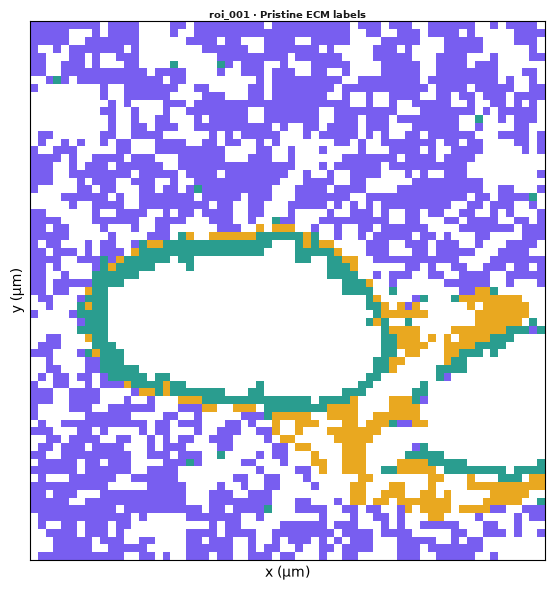

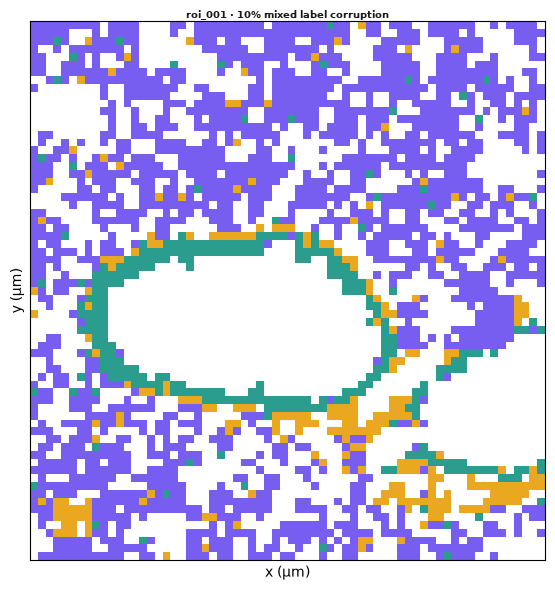

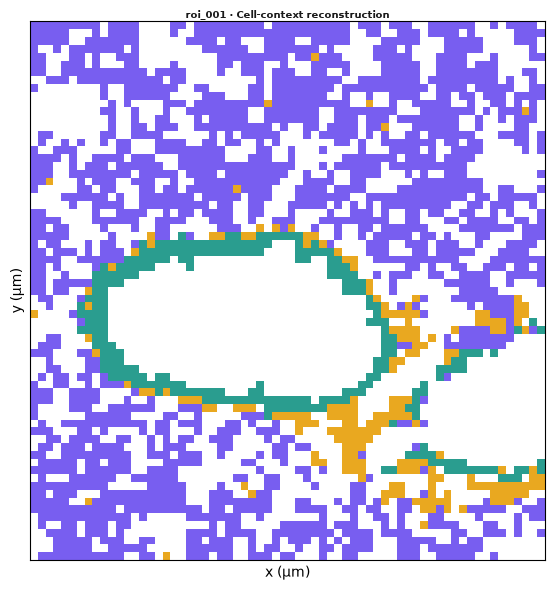

In [18]:
example_roi = next(iter(examples))
for key, label in (
    ("pristine", "Pristine ECM labels"),
    ("observed", "10% mixed label corruption"),
    ("cleaned", "Cell-context reconstruction"),
):
    H.plot_map(
        cohort.rois[example_roi], examples[example_roi][key],
        f"{example_roi} · {label}", bundle.ecm_palette,
    )

## Supplementary controls

Reuse the mouse-held-out models for block-only and isolated corruption.
Then refit the saved ROI-held-out configurations and evaluate all three
corruption types. The folds and their selected settings remain separate.
Set `RUN_SUPPLEMENTARY=False` above to run the primary experiment alone.

.\work\fig2_env\Lib\site-packages\sklearn\linear_model\_logistic.py:1221: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l1)
  warnings.warn(


.\work\fig2_env\Lib\site-packages\sklearn\linear_model\_logistic.py:1232: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(


ROI-held-out controls: roi_001


.\work\fig2_env\Lib\site-packages\sklearn\linear_model\_logistic.py:1221: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l1)
  warnings.warn(


ROI-held-out controls: roi_002


...

ROI-held-out controls: roi_004


.\work\fig2_env\Lib\site-packages\sklearn\linear_model\_logistic.py:1232: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(


ROI-held-out controls: roi_005


.\work\fig2_env\Lib\site-packages\sklearn\linear_model\_logistic.py:1221: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l1)
  warnings.warn(


ROI-held-out controls: roi_006


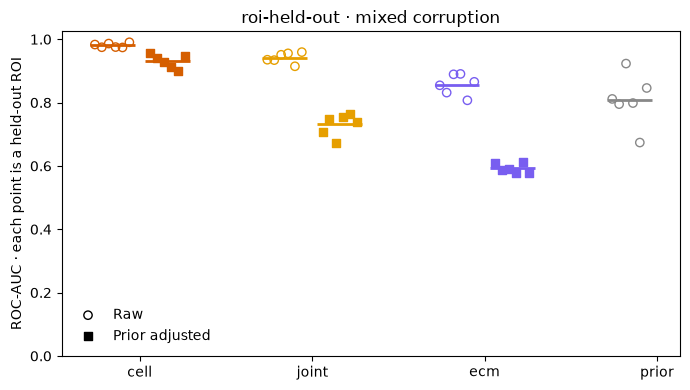

roc_auc  prior_adjusted_roc_auc  recovery  \
scheme context kind                                                  
mouse  cell    mixed      0.9660                  0.8891    0.6944   
       joint   mixed      0.9107                  0.6864    0.5193   
       ecm     mixed      0.8674                  0.6005    0.4270   
       prior   mixed      0.8081                     NaN    0.0000   
       cell    block      0.9689                  0.8892    0.7048   
               isolated   0.9653                  0.8790    0.6859   
       joint   block      0.8319                  0.4015    0.1797   
               isolated   0.9841                  0.9384    0.8404   
       ecm     block      0.7544                  0.2321    0.0263   
               isolated   0.9875                  0.9374    0.7802   
       prior   block      0.8113                     NaN    0.0000   
               isolated   0.8002                     NaN    0.0000   
roi    cell    mixed      0.9807                  0.9309    0.7747   
               block      0.9820                  0.9342    0.7705   
               isolated   0.9807                  0.9270    0.7632   
       joint   mixed      0.9417                  0.7310    0.6426   
               block      0.9028                  0.4982    0.4040   
               isolated   0.9678                  0.9152    0.7933   
       ecm     mixed      0.8564                  0.5926    0.4096   
               block      0.7457                  0.2232    0.0334   
               isolated   0.9878                  0.9259    0.7252   
       prior   mixed      0.8081                     NaN    0.0000   
               block      0.8113                     NaN    0.0000   
               isolated   0.8002                     NaN    0.0000   

                         accuracy_after  
scheme context kind                      
mouse  cell    mixed             0.9507  
       joint   mixed             0.9353  
       ecm     mixed             0.9309  
       prior   mixed             0.9000  
       cell    block             0.9517  
               isolated          0.9502  
       joint   block             0.9004  
               isolated          0.9673  
       ecm     block             0.8896  
               isolated          0.9672  
       prior   block             0.9000  
               isolated          0.9000  
roi    cell    mixed             0.9630  
               block             0.9624  
               isolated          0.9610  
       joint   mixed             0.9479  
               block             0.9241  
               isolated          0.9619  
       ecm     mixed             0.9314  
               block             0.8913  
               isolated          0.9649  
       prior   mixed             0.9000  
               block             0.9000  
               isolated          0.9000

In [19]:
started = time.perf_counter()
control_rows, control_classes = [], []
if RUN_SUPPLEMENTARY:
    for fitted in primary_fits.values():
        scores, cls, _ = H.score_fold(
            fitted, cohort, realisations, cache, kinds=("block", "isolated"),
        )
        control_rows.append(scores)
        control_classes.append(cls)
    for held_out in cohort.roi_names:
        for context in H.CONTEXTS:
            fitted = H.fit_fold(
                cohort, selected, "roi", held_out, context,
                cache, RESULTS / "checkpoints",
            )
            scores, cls, _ = H.score_fold(fitted, cohort, realisations, cache, kinds=KINDS)
            control_rows.append(scores)
            control_classes.append(cls)
            fold_records.append(H.fold_record(fitted))
        print(f"ROI-held-out controls: {held_out}")
controls = pd.concat(control_rows, ignore_index=True) if control_rows else pd.DataFrame()
control_class_counts = pd.concat(control_classes, ignore_index=True) if control_classes else pd.DataFrame()
stage_times["supplementary_controls"] = time.perf_counter() - started
if RUN_SUPPLEMENTARY:
    assert len(controls) == 600
    all_scores = pd.concat([primary, controls], ignore_index=True)
    all_per_roi, all_summary = H.summarise_scores(all_scores)
    H.plot_detection(all_per_roi, scheme="roi")
    display(all_summary.xs("mean", axis=1, level=1)[
        ["roc_auc", "prior_adjusted_roc_auc", "recovery", "accuracy_after"]
    ].round(4))

## Refit the ECM target partition within each training fold

Replay the saved signal K and classifier configuration for each of six
held-out ROIs, separately for training-cohort and per-ROI marker scaling.
Fit foreground and cluster centres on the five training ROIs, then predict
the held-out partition. The native grid contains all 4,554 tiles per ROI.

Both scaling arms receive identical physical corruption proposals on their
common foreground. Blocks can propose a label already present, so actual
corruption can be below 10%; its realised rate is reported. The per-ROI arm
uses its held-out image's pixel moments as an unsupervised transformation.
Neither arm uses held-out targets to fit centres or classifiers.

Set `RUN_TARGET_REFIT_CONTROL=False` to skip this additional control.

In [20]:
from lung_analysis import target_refit as T

target_spec = selected["target_refit_control"]
pd.DataFrame([
    {"normalization": norm, "held_out": name,
     "selected_signal_K": saved["selected_signal_k"],
     "training_ROIs": len(saved["training_rois"])}
    for norm, folds in target_spec["target_definition"].items()
    for name, saved in folds.items()
])

,normalization,held_out,selected_signal_K,training_ROIs
0,training_cohort_z,roi_001,3,5
1,training_cohort_z,roi_002,2,5
2,training_cohort_z,roi_003,3,5
3,training_cohort_z,roi_004,3,5
4,training_cohort_z,roi_005,3,5
5,training_cohort_z,roi_006,3,5
6,per_roi_z,roi_001,3,5
7,per_roi_z,roi_002,2,5
8,per_roi_z,roi_003,3,5
9,per_roi_z,roi_004,3,5


In [21]:
target_configuration_table = pd.concat([
    H.selection_table({"roi": folds}, "roi").assign(normalization=norm)
    for norm, folds in target_spec["normalization_selection"].items()
], ignore_index=True)
target_configuration_table.round(4)

,held_out,context,cell–ECM,ECM–ECM,weight,features,hops,penalty,C,threshold,passes,calibration,original_inner_score,normalization
0,roi_001,cell,delaunay,grid8,none,fraction,2,elasticnet,5.9110,2.9991,1,none,0.9742,training_cohort_z
1,roi_001,ecm,radius,radius,none,log1p_count,2,l2,0.1522,0.9476,2,temperature,0.9655,training_cohort_z
2,roi_001,joint,radius,delaunay,none,log1p_count,1,l2,0.0053,2.7904,3,none,0.9772,training_cohort_z
3,roi_002,cell,radius,grid8,none,fraction,2,l2,4.3304,2.4152,1,none,0.9710,training_cohort_z
4,roi_002,ecm,containing_ring,radius,none,log1p_count,2,elasticnet,6.0817,2.3324,2,none,0.9649,training_cohort_z
5,roi_002,joint,containing_ring,radius,inv_d,fraction,2,none,0.0057,2.9911,3,none,0.9725,training_cohort_z
6,roi_003,cell,delaunay,grid8,gaussian_median,log1p_count,2,elasticnet,0.1173,2.6893,1,none,0.9705,training_cohort_z
7,roi_003,ecm,containing_ring,delaunay,none,log1p_count,2,elasticnet,0.0141,0.3531,1,none,0.9511,training_cohort_z
8,roi_003,joint,radius,grid8,inv_d,log1p_count,2,elasticnet,34.7393,0.9463,3,none,0.9703,training_cohort_z
9,roi_004,cell,knn,grid8,gaussian_median,log1p_count,1,l2,0.0029,0.9490,1,temperature,0.9709,training_cohort_z


In [22]:
started = time.perf_counter()
target_rows, target_classes, target_records, target_fold_records = [], [], [], []
if RUN_SUPPLEMENTARY and RUN_TARGET_REFIT_CONTROL:
    raw_stats = T.raw_statistics(bundle, PATCH_SIZE)
    geometry = T.geometry_from_bundle(bundle, raw_stats, PATCH_SIZE)
    target_dir = RESULTS / "training_fold_targets"
    target_dir.mkdir(parents=True, exist_ok=True)
    for held_out in geometry.roi_names:
        target_cohorts, target_caches = {}, {}
        for normalization in T.NORMALIZATIONS:
            native, native_cache, target_record = T.refit_targets(
                geometry, raw_stats, selected, normalization, held_out,
                RESULTS / "checkpoints",
            )
            target_cohorts[normalization] = native
            target_caches[normalization] = native_cache
            target_records.append(target_record)
            H.export_partition(
                native, target_dir / f"{normalization}_{held_out}_partition.csv",
            )
        paired = T.paired_corruptions(
            target_cohorts, held_out, kinds=KINDS, seeds=EVALUATION_SEEDS,
        )
        for normalization, native in target_cohorts.items():
            native_cache = target_caches[normalization]
            saved_folds = target_spec["normalization_selection"][normalization]
            for context in ("cell", "ecm", "joint"):
                fitted = H.fit_fold(
                    native, {"roi": saved_folds}, "roi", held_out, context,
                    native_cache, RESULTS / "checkpoints",
                )
                measured, cls, example = T.score_target_fold(
                    fitted, native, paired, native_cache, normalization,
                )
                target_rows.append(measured)
                target_classes.append(cls)
                record = H.fold_record(fitted) | {"normalization": normalization}
                target_fold_records.append(record)
                np.savez_compressed(
                    target_dir / f"{normalization}_{held_out}_{context}_mixed_seed0.npz",
                    **example,
                )
        print(f"Training-fold targets: {held_out} · two scaling arms")
target_scores = pd.concat(target_rows, ignore_index=True) if target_rows else pd.DataFrame()
target_class_counts = pd.concat(target_classes, ignore_index=True) if target_classes else pd.DataFrame()
stage_times["training_fold_target_control"] = time.perf_counter() - started
if not target_scores.empty:
    assert len(target_scores) == 540 and len(target_fold_records) == 36
    assert len(target_records) == 12
    assert target_scores.groupby(
        ["normalization", "context", "outer_roi", "kind"]
    ).size().eq(5).all()
    target_per_roi, target_summary = T.summarise_target_scores(target_scores)
    display(target_summary[[
        "roc_auc", "prior_adjusted_roc_auc_full_signal", "recovery",
        "accuracy_after", "realized_corruption_fraction",
        "macro_f1_after_common_signal",
    ]].round(4))

.\work\fig2_env\Lib\site-packages\sklearn\linear_model\_logistic.py:1221: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l1)
  warnings.warn(


Training-fold targets: roi_001 · two scaling arms


.\work\fig2_env\Lib\site-packages\sklearn\linear_model\_logistic.py:1232: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(


.\work\fig2_env\Lib\site-packages\sklearn\linear_model\_logistic.py:1232: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(


.\work\fig2_env\Lib\site-packages\sklearn\linear_model\_logistic.py:1221: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l1)
  warnings.warn(


...

.\work\fig2_env\Lib\site-packages\sklearn\linear_model\_logistic.py:1221: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l1)
  warnings.warn(


.\work\fig2_env\Lib\site-packages\sklearn\linear_model\_logistic.py:1232: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(


.\work\fig2_env\Lib\site-packages\sklearn\linear_model\_logistic.py:1232: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(


Training-fold targets: roi_006 · two scaling arms


roc_auc  \
normalization     context kind                
training_cohort_z cell    mixed      0.9800   
                          block      0.9714   
                          isolated   0.9808   
                  ecm     mixed      0.9289   
                          block      0.8350   
                          isolated   0.9880   
                  joint   mixed      0.9697   
                          block      0.9303   
                          isolated   0.9908   
per_roi_z         cell    mixed      0.9772   
                          block      0.9668   
                          isolated   0.9766   
                  ecm     mixed      0.9205   
                          block      0.8166   
                          isolated   0.9867   
                  joint   mixed      0.9676   
                          block      0.9259   
                          isolated   0.9902   

                                    prior_adjusted_roc_auc_full_signal  \
normalization     context kind                                           
training_cohort_z cell    mixed                                 0.9114   
                          block                                 0.8667   
                          isolated                              0.9186   
                  ecm     mixed                                 0.6438   
                          block                                 0.2051   
                          isolated                              0.9022   
                  joint   mixed                                 0.7894   
                          block                                 0.5170   
                          isolated                              0.9440   
per_roi_z         cell    mixed                                 0.8952   
                          block                                 0.8528   
                          isolated                              0.9058   
                  ecm     mixed                                 0.6700   
                          block                                 0.2472   
                          isolated                              0.9180   
                  joint   mixed                                 0.7658   
                          block                                 0.4507   
                          isolated                              0.9476   

                                    recovery  accuracy_after  \
normalization     context kind                                 
training_cohort_z cell    mixed       0.7432          0.9702   
                          block       0.6877          0.9765   
                          isolated    0.7482          0.9665   
                  ecm     mixed       0.5168          0.9506   
                          block       0.0379          0.9333   
                          isolated    0.7934          0.9732   
                  joint   mixed       0.6731          0.9636   
                          block       0.3573          0.9525   
                          isolated    0.8551          0.9774   
per_roi_z         cell    mixed       0.7071          0.9707   
                          block       0.6293          0.9757   
                          isolated    0.7055          0.9668   
                  ecm     mixed       0.5418          0.9556   
                          block       0.0602          0.9390   
                          isolated    0.7745          0.9721   
                  joint   mixed       0.6431          0.9632   
                          block       0.2451          0.9483   
                          isolated    0.8550          0.9777   

                                    realized_corruption_fraction  \
normalization     context kind                                     
training_cohort_z cell    mixed                           0.0804   
                          block                           0.0598   
                          isolated                        0.0

fresh fit                 \
                                  roc_auc accuracy_after   
normalization     context kind                             
training_cohort_z cell    mixed    0.9800         0.9702   
per_roi_z         cell    mixed    0.9772         0.9707   

                                                             paper reference  \
                                macro_f1_after_common_signal         roc_auc   
normalization     context kind                                                 
training_cohort_z cell    mixed                       0.9252          0.9800   
per_roi_z         cell    mixed                       0.9216          0.9772   

                                                                             
                                accuracy_after macro_f1_after_common_signal  
normalization     context kind                                               
training_cohort_z cell    mixed         0.9702                       0.9252  
per_roi_z         cell    mixed         0.9707                       0.9216

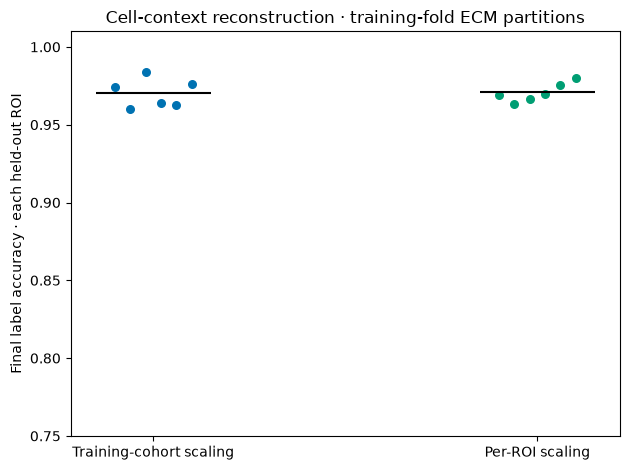

In [23]:
if not target_scores.empty:
    reference_target = pd.DataFrame(target_spec["paper_reference"]).set_index(
        ["normalization", "context", "kind"]
    )
    comparison_target = pd.concat({
        "fresh fit": target_summary[reference_target.columns],
        "paper reference": reference_target,
    }, axis=1)
    display(comparison_target.loc[
        pd.IndexSlice[:, "cell", "mixed"],
        pd.IndexSlice[:, ["roc_auc", "accuracy_after", "macro_f1_after_common_signal"]],
    ].round(4))
    mixed = target_per_roi.query("context == 'cell' and kind == 'mixed'")
    for i, normalization in enumerate(T.NORMALIZATIONS):
        values = mixed.loc[mixed.normalization.eq(normalization)]
        plt.scatter(
            i + np.linspace(-0.10, 0.10, len(values)),
            values["accuracy_after"], s=30,
            c="#0072B2" if i == 0 else "#009E73",
        )
        plt.hlines(values["accuracy_after"].mean(), i - 0.15, i + 0.15,
                   color="black", linewidth=1.5)
    plt.xticks([0, 1], ["Training-cohort scaling", "Per-ROI scaling"])
    plt.ylabel("Final label accuracy · each held-out ROI")
    plt.ylim(0.75, 1.01)
    plt.title("Cell-context reconstruction · training-fold ECM partitions")
    plt.tight_layout()
    plt.show()

## Save results and timings

In [24]:
H.export_partition(cohort, RESULTS / "fresh_partition.csv")
association.to_csv(RESULTS / "celltype_association.csv", index=False)
per_roi_association.to_csv(RESULTS / "association_per_roi.csv", index=False)
contrasts.to_csv(RESULTS / "aec_marker_contrasts.csv")
graph_counts.to_csv(RESULTS / "descriptive_graph_counts.csv", index=False)
pd.DataFrame(primary_support).to_csv(RESULTS / "primary_patch_eligibility.csv", index=False)
sensitivity.to_csv(RESULTS / "aec_graph_sensitivity.csv", index=False)
primary.to_csv(RESULTS / "mouse_held_out_metrics.csv", index=False)
per_roi_scores.to_csv(RESULTS / "mouse_held_out_metrics_per_roi.csv", index=False)
class_counts.to_csv(RESULTS / "mouse_held_out_class_counts.csv", index=False)
recovery_summary.to_csv(RESULTS / "mouse_held_out_class_recovery.csv", index=False)
comparison.to_csv(RESULTS / "fresh_vs_paper_reference.csv")
if RUN_SUPPLEMENTARY:
    controls.to_csv(RESULTS / "supplementary_control_metrics.csv", index=False)
    control_class_counts.to_csv(RESULTS / "supplementary_class_counts.csv", index=False)
if not target_scores.empty:
    target_scores.to_csv(RESULTS / "training_fold_target_metrics.csv", index=False)
    target_per_roi.to_csv(RESULTS / "training_fold_target_metrics_per_roi.csv", index=False)
    target_class_counts.to_csv(RESULTS / "training_fold_target_class_counts.csv", index=False)
    comparison_target.to_csv(RESULTS / "training_fold_targets_fresh_vs_paper.csv")
    (RESULTS / "training_fold_target_provenance.json").write_text(json.dumps({
        "target_definitions": target_records,
        "classifier_folds": target_fold_records,
        "corruption_roi_seed": target_spec["corruption_seed"],
        "physical_proposals_paired_across_normalizations": True,
        "aggregation": "mean seeds within ROI; mean ROIs with equal weight",
        "optimisation_rerun": False,
    }, indent=2))
for name, maps in examples.items():
    np.savez_compressed(RESULTS / f"{name}_cell_context_example.npz", **maps)
stage_times["total_analysis_and_export"] = time.perf_counter() - experiment_started
provenance = {
    "scope": "Fresh full lung fits using published fold-specific selections",
    "optimisation_rerun": False,
    "identity": H.run_identity(cohort),
    "roi_order": cohort.roi_names,
    "evaluation_seeds": EVALUATION_SEEDS,
    "corruption_roi_seed": "evaluation_seed * 1000 + ROI index",
    "fit_seed": 0,
    "primary_fits": 8,
    "primary_score_rows": len(primary),
    "supplementary_fits": 24 if RUN_SUPPLEMENTARY else 0,
    "supplementary_score_rows": len(controls),
    "training_fold_target_kmeans_fits": len(target_records),
    "training_fold_target_classifier_fits": len(target_fold_records),
    "training_fold_target_score_rows": len(target_scores),
    "aggregation": "mean seeds within ROI; mean ROIs with equal weight",
    "class_recovery": "sum counts across seeds within ROI; equal-weight ROI mean",
    "partition": {"total_patches": total, "signal_patches": signal,
                  "source": "fresh Mantpy K=4 fit",
                  "patch_eligibility": primary_support},
    "folds": fold_records,
    "stage_times_seconds": stage_times,
    "controls_not_recomputed": selected["unsupported_controls"],
}
(RESULTS / "run_provenance.json").write_text(json.dumps(provenance, indent=2))
print(f"Saved results to {RESULTS.resolve()}")
pd.Series(stage_times, name="seconds").round(2)

Saved results to .\outputs\notebook_api_implementation\full_after\workspaces\lung\results\lung


data_loading                            0.92
partition                               3.08
descriptive_graphs_and_association      7.82
graph_sensitivity                     197.95
mouse_held_out_fitting_and_scoring     23.70
supplementary_controls                 76.29
training_fold_target_control          139.01
total_analysis_and_export             452.11
Name: seconds, dtype: float64